# 08 · Is the result real? Alpha, beta and the competition

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/08_alpha_beta_competition.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

In notebook 02 you saw that the best of many no-skill strategies looks skilful by luck. This notebook gives that idea a number. A strategy that made 20% in a year when the market made 25% did not do well. A strategy that made 10% while the market fell did. To judge a strategy fairly you have to take the market out first. **Beta** and **alpha** do exactly that.

**What you'll do (~60 min):**
1. Move **beta**, **alpha** and **luck** sliders and watch the line
2. The maths in one line, then real ETFs
3. See why a high alpha can still be luck, or a cheat
4. Write **your own strategy**, score it, and enter the **alpha competition**

The interactive explainer is in section 1 below. It is also a web page you can open on your phone: [alpha and beta, with sliders](https://kolyamkl.github.io/qm-fintech-quant-workshop/alpha-beta.html).

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

Run this cell first. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them.

In [1]:
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/aurvyl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

## 1. Move the line

Run the cell below. Each dot is one made-up month: across is what the market made above cash, up is what a strategy made above cash.

- **Beta** sets the slope: how much the strategy moves when the market moves 1%.
- **Alpha** sets where the line crosses zero: what it makes in a month when the market does nothing.
- **Luck** scatters the dots around the line. Watch the *measured* alpha under the chart drift away from the true one as luck grows, and press **Draw 48 new months** a few times.

✏️ **Try it:** set alpha to 0 and luck to 4%. How often does the measured alpha still look good?

In [2]:
from backtester.alpha import explainer

explainer()

## 2. One dot per month, in real data

Take every month. Work out two numbers:
- **the market's return above cash**: what SPY made that month, minus what a savings account paid
- **your return above cash**: the same for your strategy

Plot one dot per month, market across, you up. Then draw the best straight line through the dots:

$$\underbrace{R_{you} - R_{cash}}_{\text{your excess return}} \;=\; \alpha \;+\; \beta\,\underbrace{(R_{market} - R_{cash})}_{\text{market excess return}} \;+\; \text{noise}$$

- **β (beta)** is the **slope**. β = 1.5 means: when the market beats cash by 1%, you tend to beat it by 1.5%. When it loses 1%, you tend to lose 1.5%. Beta is risk you could have bought cheaply with an index fund.
- **α (alpha)** is the **height where the line crosses zero**: what you made in a month when the market did nothing. That is the part the market cannot explain. It is what fund managers are paid for.

Annualised alpha here is simply monthly alpha × 12.

"Best line" means **least squares**: the slope and height that make the squared vertical distances from the dots to the line as small as possible:

$$\beta = \frac{\operatorname{cov}(x, y)}{\operatorname{var}(x)}, \qquad \alpha = \bar{y} - \beta\,\bar{x}$$

In this workshop the market is **SPY** and cash pays a flat **3% a year**, a simple stand-in for a savings rate.

In [3]:
from backtester import load_closes
from backtester.alpha import alpha_beta, CASH_RATE, MARKET

closes = load_closes(["SPY", "QQQ", "XLU", "TLT", "GLD"]).dropna()
daily = closes.pct_change().iloc[1:]

nasdaq = alpha_beta(daily["QQQ"], daily["SPY"])
pd.Series(nasdaq.summary(), name="QQQ against SPY, 2016 to 2026")

Beta                 1.14
Alpha per month    +0.28%
Alpha per year      +3.4%
Alpha t-stat         1.39
R squared            0.83
Months                130
Name: QQQ against SPY, 2016 to 2026, dtype: str

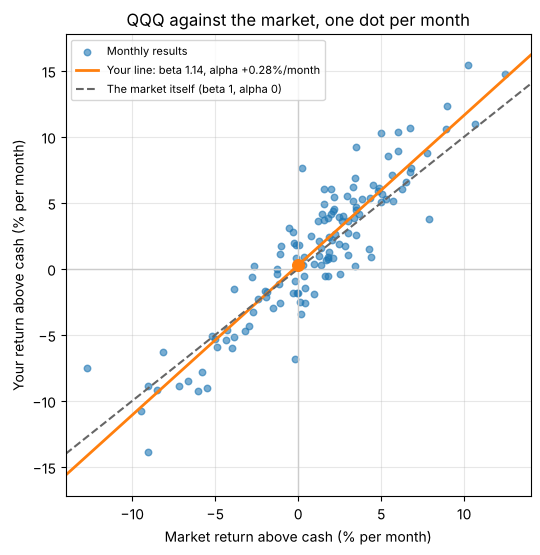

In [4]:
nasdaq.plot("QQQ against the market, one dot per month")

Read the chart:
- The **orange line** is steeper than the **dashed market line**: QQQ's beta is above 1. It swings more than the market both ways.
- The big orange dot is where the line crosses zero: that height is alpha.
- **R squared** says how much of QQQ's monthly ups and downs the market explains (1 = all of it).

## 3. Five assets, five personalities

✏️ **Try it:** before you run the cell, guess each beta. Utilities (XLU)? Long bonds (TLT)? Gold (GLD)?

In [5]:
table = {}
for ticker in ["SPY", "QQQ", "XLU", "TLT", "GLD"]:
    table[ticker] = alpha_beta(daily[ticker], daily["SPY"]).summary()
pd.DataFrame(table)

,SPY,QQQ,XLU,TLT,GLD
Beta,1.00,1.14,0.47,0.15,0.12
Alpha per month,+0.00%,+0.28%,+0.13%,-0.43%,+0.75%
Alpha per year,+0.0%,+3.4%,+1.6%,-5.2%,+9.1%
Alpha t-stat,nan,1.39,0.37,-1.24,1.85
R squared,1.00,0.83,0.21,0.03,0.01
Months,130,130,130,130,130


What to notice:
- **SPY against itself** has beta exactly 1 and alpha 0. That is the market line.
- **Low beta is not the same as no risk.** TLT and GLD barely follow the stock market, but they had big falls of their own (bonds in 2022).
- An asset can have positive alpha against SPY just by being a different asset. Alpha against one market is not proof of skill.

## 4. Is that alpha real?

This is the luck trap from notebook 02, now measured. Every alpha is an **estimate** from a limited number of noisy months. The **t-stat** is alpha divided by its uncertainty (its standard error). A rough rule: **below 2, the alpha could easily be luck**.

The cell below invents 1,000 strategies with **zero true skill** (true alpha = 0, beta = 1, plus noise) and measures each one over 4 years. Some of them will look brilliant.

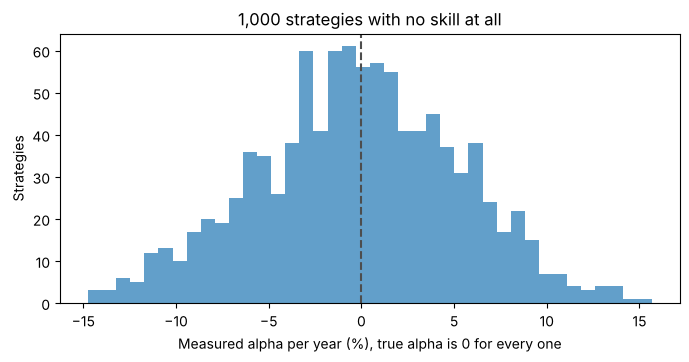

Best 'alpha' found by luck: +15.7% a year
Share with t-stat above 2: 2.4%


In [6]:
import numpy as np

rng = np.random.default_rng(7)
months = pd.period_range("2023-01", periods=48, freq="M").to_timestamp(how="end").normalize()
market = pd.Series(rng.normal(0.008, 0.045, len(months)), index=months)
lucky = []
for i in range(1000):
    no_skill = market + rng.normal(0, 0.03, len(months))
    fit = alpha_beta(no_skill, market, cash_rate=0.0)
    lucky.append({"alpha_per_year": fit.alpha_annual, "t_stat": fit.alpha_t})
lucky = pd.DataFrame(lucky)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(lucky["alpha_per_year"] * 100, bins=40, color="tab:blue", alpha=0.7)
ax.axvline(0, color="0.3", ls="--")
ax.set_xlabel("Measured alpha per year (%), true alpha is 0 for every one")
ax.set_ylabel("Strategies")
ax.set_title("1,000 strategies with no skill at all")
plt.show()
print(f"Best 'alpha' found by luck: {lucky['alpha_per_year'].max():+.1%} a year")
print(f"Share with t-stat above 2: {(lucky['t_stat'] > 2).mean():.1%}")

So if 100 students each try 10 ideas and only report the best, **someone wins by luck**. Two defences, both used in the competition below:
1. **Score on data you did not build on.** Build and tune on 2016 to 2022; the score comes only from **2023 onwards**, and the organiser keeps those scores from you until the deadline.
2. **Look at the t-stat**, not just the alpha.

A third trap is a strategy that **peeks at the future**. The competition checks every strategy by flipping every price move after a date and running it again. An honest strategy makes exactly the same choices up to that date. A peeking one does not.

## 5. The alpha competition

### The rules
| | |
|---|---|
| **Data** | The fixed `data/prices.csv`: 24 ETFs and stocks, 2016 to Oct 2026. Every entry gets the same `closes`. |
| **Your strategy** | A function `strategy(closes)` that returns **weights**: one row per day, one column per ticker. |
| **Weights** | 0 or more, each row adds up to **at most 1**. Whatever is left is cash and earns 3% a year. No shorting, no leverage. |
| **Timing** | Weights decided at a day's close are held from the next day. The one-day delay is applied for you. |
| **Costs** | 5 basis points (0.05%) on every trade. |
| **Market** | SPY. Cash: 3% a year. Monthly returns above cash. |
| **Build period** | 2016 to 2022: tune here as much as you like. You see these numbers, but they are **not scored**. |
| **Scored** | **2023 onwards, held back by the organiser.** You never see your own scored result until the deadline. |
| **Ranking** | By the **t-stat of the scored alpha**, so a lucky big alpha cannot win. A win needs a t-stat of **2 or more**. Ties go to the higher alpha. |
| **Out** | Using future prices, loading data yourself instead of `closes`, weights that break the rules, never investing. |

The organiser runs every entry with the same code. Your numbers here are a preview of the build period and of the checks only.

### The house strategies to beat

Some of these are simple, one is a cheat. Run the cell (it takes a few seconds). It shows the build period only, ordered by the t-stat of the build-period alpha.

In [7]:
from backtester.alpha import score, preview_leaderboard, format_leaderboard
from competition.examples import HOUSE

house = [score(fn, name) for name, fn in HOUSE.items()]
format_leaderboard(preview_leaderboard(house))

,Strategy,Build-period alpha / year,Build-period beta,Build-period alpha t-stat,Status
Order,,,,,
1,House: peeks at tomorrow (cheat),+100.3%,-0.05,10.53,Out: uses future prices (seen on 2017-01-30)
2,"House: sector momentum, top 3",+3.1%,0.85,1.10,OK so far
3,House: hold the Nasdaq (QQQ),+2.1%,1.10,0.73,OK so far
4,House: trend or bonds,-1.3%,0.58,-0.34,OK so far
5,House: hold the market (SPY),-0.0%,1.00,-1.15,OK so far
6,"House: half market, half cash",-0.6%,0.60,-2.10,OK so far


What to notice:
- **Hold the market** has an alpha of about zero by definition and a beta of 1.
- **Sector momentum** has the best honest alpha in the build period, but its t-stat is only about 1. Under 2 means it could easily be luck, so it has not proved anything yet.
- **The cheat** has an enormous alpha and is thrown out by the look-ahead check.
- The scored period is not shown. When the organiser reveals it after the deadline, compare that table with this one: that gap is what tuning on the past looks like.

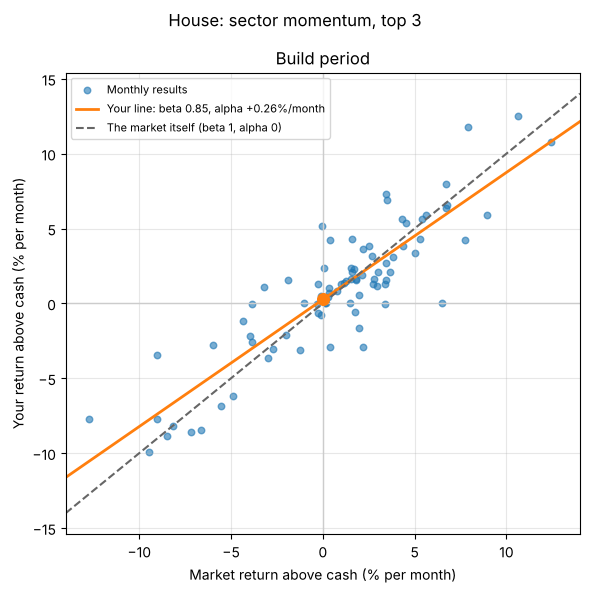

In [8]:
house[3].plot()

## 6. ✏️ Your strategy

Edit the function below and re-run the cells after it. Ideas:
- **Momentum:** hold the tickers that rose most over the last 3, 6 or 12 months.
- **Trend filter:** only hold stocks when SPY is above its 200-day average; otherwise bonds or gold.
- **Low volatility:** hold the calmest assets.
- **Mix:** split the money between two ideas.

Useful pieces: `closes.pct_change()`, `.rolling(n).mean()`, `.rolling(n).std()`, `.shift(n)` with **positive** `n` only (a negative shift reads the future), and from `backtester.portfolio`: `top_n_weights(scores, n, on=month_ends(closes.index))`.

Tickers: `SPY QQQ IWM DIA XLK XLF XLE XLV XLY XLP XLI XLU XLB AAPL MSFT AMZN GOOGL JPM JNJ XOM PG TLT IEF GLD`

In [9]:
from backtester.portfolio import month_ends, top_n_weights

TEAM = "My team"


def strategy(closes):
    stocks = ["AAPL", "MSFT", "AMZN", "GOOGL", "JPM", "JNJ", "XOM", "PG"]
    momentum = closes[stocks] / closes[stocks].shift(126) - 1
    weights = top_n_weights(momentum, 3, on=month_ends(closes.index))
    trend_up = closes["SPY"] > closes["SPY"].rolling(200).mean()
    return weights.mul(trend_up, axis=0)


mine = score(strategy, TEAM)
mine.summary()

My team,Build period 2016 to 2022
Beta,0.61
Alpha per month,+0.97%
Alpha per year,+11.6%
Alpha t-stat,2.30
R squared,0.36
Months,84


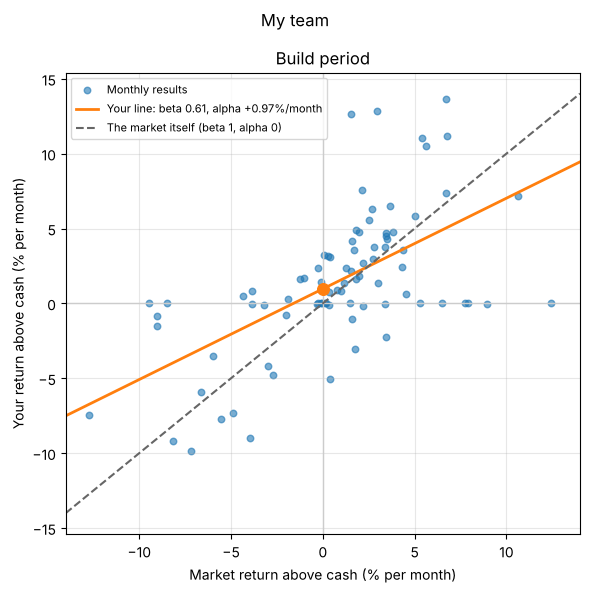

In [10]:
mine.plot()

### How does it look next to the house strategies?

In [11]:
format_leaderboard(preview_leaderboard(house + [mine]))

,Strategy,Build-period alpha / year,Build-period beta,Build-period alpha t-stat,Status
Order,,,,,
1,House: peeks at tomorrow (cheat),+100.3%,-0.05,10.53,Out: uses future prices (seen on 2017-01-30)
2,My team,+11.6%,0.61,2.30,OK so far
3,"House: sector momentum, top 3",+3.1%,0.85,1.10,OK so far
4,House: hold the Nasdaq (QQQ),+2.1%,1.10,0.73,OK so far
5,House: trend or bonds,-1.3%,0.58,-0.34,OK so far
6,House: hold the market (SPY),-0.0%,1.00,-1.15,OK so far
7,"House: half market, half cash",-0.6%,0.60,-2.10,OK so far


**Questions to discuss:**
- Your build-period alpha looks good. What would convince you it is not luck: a higher t-stat, more months, or a result on data you have not touched?
- Is an alpha of +3% with a t-stat of 0.8 better than +1% with a t-stat of 2.5?
- Why does the organiser hide the scored period? What happens to a test the moment you can see it and change your strategy?
- Sector momentum has the best build-period alpha among the house strategies. Would you enter it?

## 7. Submit your entry

1. Copy `competition/entries/example_team.py` to `competition/entries/<your_team>.py`.
2. Set `TEAM` and paste your `strategy` function into it (plus any imports it needs).
3. Send the file to the organiser (or open a pull request to your fork). **One entry per team.**

The organiser then runs `python scripts/leaderboard.py`, which scores every entry the same way on the held-back period, ranks by the t-stat, and writes `competition/leaderboard.md`. If new price data comes in after the deadline, the organiser can re-run it on months nobody had seen when they wrote their strategy: the fairest test there is.

### Next: an AI agent that has to follow the rules

A language model proposes how to react to a crash. The same fixed gate from notebook 07 decides whether the proposal is allowed.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/09_ai_risk_agent.ipynb) `09_ai_risk_agent.ipynb`